# Training AggFace

AggFace takes several anonymized frames of one person and produces a single clear face. One training item is therefore a whole identity: N anonymized observations, and the one clear target `05` picked for them.

Three parts in a row - an **encoder** that turns each frame into a 512x7x7 feature map, an **aggregator** that pools the N maps into one, and a **decoder** that expands that back into a 3x112x112 face. The bottleneck is the point and the difficulty: 25,088 values carry the whole reconstruction, and unlike a U-Net there is no skip path from the inputs.

Two schedules run during training and they are independent:

- the **curriculum** widens which anonymizations the data holds, clear frames first and black bars last, because the hardest of them removes the face outright and a model shown it from the first epoch has no signal to learn from;
- the **encoder schedule** holds the pretrained encoder fixed at first and fine-tunes it afterwards at a tenth of the learning rate.

The whole run is repeated across several **seeds**, because a single run cannot tell an effect from an initialisation.

## The encoder's starting weights

The encoder begins from an `iresnet34` backbone trained for face recognition, so it starts out already knowing what makes faces distinguishable. The same network, frozen and separate, is also the identity critic.

Those weights are **not downloaded automatically**. InsightFace distributes the `arcface_torch` backbones through OneDrive rather than from a stable URL, so there is nothing to fetch from and nothing to checksum at a URL - the file is pinned by digest instead.

To get it:

1. Open the [InsightFace model zoo](https://github.com/deepinsight/insightface/tree/master/model_zoo) and follow it to the `arcface_torch` backbones, or use the direct share: <https://1drv.ms/u/s!AswpsDO2toNKq0lWY69vN58GR6mw>
2. Save the `iresnet34` backbone as `models/iresnet34.pth` in this repository.
3. Run the cell below, which fails with the expected digest if the file is missing or different.

The exact training recipe behind this particular file is not recorded upstream, which is why its SHA-256 rather than a name is what identifies it.

In [1]:
from aggface.model import IRESNET34
from meles import weights

path = weights.resolve(IRESNET34)
digest = weights.digest(path)
assert digest == IRESNET34.sha256, f"{path} has digest {digest}, expected {IRESNET34.sha256}"
print(f"{path} ({path.stat().st_size / 1e6:.0f} MB) matches its expected digest")

/data/projects/personal/meles/models/iresnet34.pth (137 MB) matches its expected digest


## The items

Training uses the **train** identities and validation the **validation** ones, both from `02`. They share no person, so a validation loss measures whether the decoder generalises rather than how well it memorised a face.

The validation set differs from the training set in two deliberate ways. It is **deterministic**, drawing the same frames and the same anonymization every epoch, because a loss measured over freshly drawn frames is not comparable between epochs. And it yields every identity under **every** anonymization rather than one drawn per identity, which pairs the comparison: each method sees the same person on the same frames, so a difference between two methods is the anonymization and nothing else.

In [2]:
import multiprocessing
import os
from concurrent.futures import ProcessPoolExecutor

import cv2
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from torch import Tensor
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

from aggface.data import AREA_COLUMNS, CURRICULUM, LANDMARK_COLUMNS, Items
from aggface.losses import IdentityLoss, WeightedCriterion, l1_per_item
from aggface.model import AggFace, checkpoint_path
from aggface.tensors import to_image
from aggface.training import Trainer, identification, load_model, reconstruct
from meles.detection import default_detector
from meles.paths import repository_root
from meles.recognition import ARCFACE, FrameEmbedder

sns.set_theme(style="whitegrid")

ROOT = repository_root()
DATA = ROOT / "data"
AREAS = DATA / "voxceleb2_areas.parquet"

RUN = "voxceleb2"
# SEEDS = (0,)
SEEDS = (0, 1, 2, 3, 4)
FRAMES = 8  # observations per item, the N the model is trained with
BATCH = 16
# Fine-tuning unfreezes the encoder, so the activations of all BATCH x FRAMES encoder passes
# have to be kept for the backward pass instead of none. A smaller batch is what keeps that in
# GPU memory; the first phase does not need it.
FINE_TUNE_BATCH = 4
WORKERS = 4
DETECT_CHUNK = 5000  # frames per detection task
EPOCHS_PER_STAGE = 25
FINE_TUNE_EPOCHS = 25
WIDTH = 2.0  # decoder width multiplier
DROPOUT = 0.0
# The identity term's weight beside an L1 of 1.0, set so the two start out comparable in
# magnitude rather than by tuning: L1 settles near 0.3 while '1 - cos' between unrelated faces is
# close to 1.0.
IDENTITY_WEIGHT = 0.3

structure = pd.read_parquet(DATA / "voxceleb2.parquet", columns=["identity", "video", "path"])
split = pd.read_parquet(DATA / "voxceleb2_split.parquet")
targets = pd.read_parquet(DATA / "voxceleb2_targets.parquet")

identities = {part: list(split.loc[split["split"] == part, "identity"]) for part in ("train", "validation")}
print(f"{len(identities['train']):,} train and {len(identities['validation']):,} validation identities")


5,094 train and 300 validation identities


### Where the faces are

Every crop is built from a face located on the **clear** frame, so the same area both anonymizes and aligns. Detecting during training would mean every data loader worker running a detector and remembering its answers, which grows without bound across epochs - so the detections are done once, here, and written to `data/voxceleb2_areas.parquet`.

One pass over the corpus, around twenty minutes spread over the cores. It is cached, and the experiment's own detection stage reads the same table.


In [3]:
def detect_frames(paths: list[str]) -> pd.DataFrame:
    """The face found in each frame, as flat columns."""
    rows = []
    for path in paths:
        area = default_detector.detect(cv2.imread(str(DATA / path)))
        landmarks = area.landmarks.reshape(-1) if area else np.zeros(10, dtype=np.float32)
        rows.append(
            {
                "path": path,
                "x": area.x if area else 0,
                "y": area.y if area else 0,
                "w": area.w if area else 0,
                "h": area.h if area else 0,
                "found": area is not None,
                **dict(zip(LANDMARK_COLUMNS, landmarks)),
            }
        )
    return pd.DataFrame(rows)


if AREAS.exists():
    areas = pd.read_parquet(AREAS)
else:
    paths = list(structure["path"])
    tasks = [paths[start : start + DETECT_CHUNK] for start in range(0, len(paths), DETECT_CHUNK)]

    context = multiprocessing.get_context("fork")
    with ProcessPoolExecutor(max_workers=max(1, (os.cpu_count() or 2) - 1), mp_context=context) as pool:
        parts = list(tqdm(pool.map(detect_frames, tasks), total=len(tasks), desc=f"{DETECT_CHUNK}-frame chunks"))

    areas = pd.concat(parts, ignore_index=True)
    areas.to_parquet(AREAS, index=False)

print(f"{len(areas):,} frames, {(~areas['found']).sum():,} without a detected face")
areas[list(AREA_COLUMNS)].head()


3,400,602 frames, 0 without a detected face


,x,y,w,h,found
0,49,2,132,167,True
1,49,3,125,168,True
2,49,4,121,167,True
3,53,2,124,165,True
4,49,3,131,161,True


In [4]:
shared = dict(structure=structure, targets=targets, areas=areas, root=DATA, curriculum=CURRICULUM, frames=FRAMES)


def training_items(stage: int) -> Items:
    """The training set widened to a curriculum stage."""
    return Items(**shared, identities=identities["train"], stage=stage)


# Pinned to the last stage, so every method is measured from the first epoch and a method has a
# baseline to be compared against on the epoch it unlocks.
validation_items = Items(
    **shared,
    identities=identities["validation"],
    stage=len(CURRICULUM) - 1,
    deterministic=True,
    all_methods=True,
    flip=False,
)

print(f"train:      {len(training_items(0)):,} identities")
print(f"validation: {len(validation_items):,} items ({validation_items.stages} methods x identities)")


train:      5,094 identities
validation: 1,200 items (4 methods x identities)


One item, as the model receives it: N anonymized observations of a person drawn from different videos, and the single clear target the decoder has to produce from them.

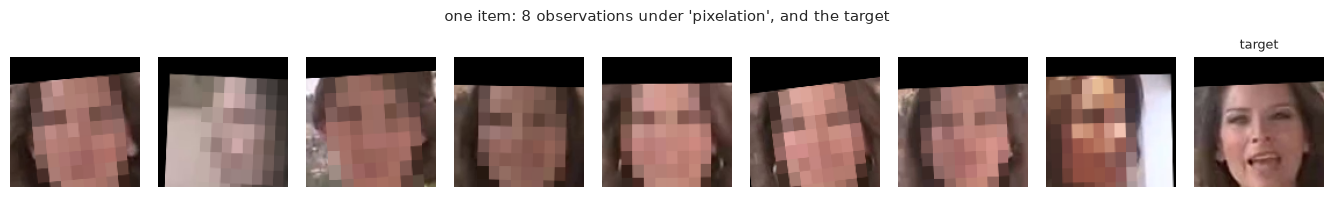

In [5]:
anonymized, clear, method = validation_items[len(CURRICULUM) * 3 + 2]

fig, axes = plt.subplots(1, FRAMES + 1, figsize=(1.5 * (FRAMES + 1), 2.0))
for axis, frame in zip(axes, anonymized):
    axis.imshow(to_image(frame)[:, :, ::-1])
    axis.set_axis_off()
axes[-1].imshow(to_image(clear)[:, :, ::-1])
axes[-1].set_axis_off()
axes[-1].set_title("target", fontsize=9)
fig.suptitle(f"one item: {FRAMES} observations under '{CURRICULUM[method]}', and the target", fontsize=11)
fig.tight_layout()
plt.show()

## What the run is steered by

The loss has two terms. **L1** asks for the right pixels, and its cheapest answer under uncertainty is a blurry average face - low error against everyone, identifying as no one. **Identity** asks for the right person, as cosine distance between a recognizer's embeddings of the reconstruction and of the target, which is what removes that incentive.

Neither is the number the experiment reports. That is **rank-1 identification**: how often a reconstruction's nearest gallery face is the right person. It is measured each epoch with ArcFace, which is deliberately *not* the critic the loss uses - otherwise the run would be grading its own work. The reconstructions are already aligned 112x112 crops, so they go straight into the recognizer without being detected again.

In [6]:
arcface = FrameEmbedder(ARCFACE)


def embed(batch: Tensor) -> np.ndarray:
    """L2-normalised ArcFace embeddings of aligned crops, with no detection step."""
    vectors = arcface.embed_crops([to_image(frame) for frame in batch])
    return vectors / np.linalg.norm(vectors, axis=1, keepdims=True)


def rank_1(trainer: Trainer) -> dict[str, float]:
    """Rank-1 identification over the validation items, overall and per anonymization."""
    return identification(trainer.model, validation_items, embed, ranks=(1,))


## The run

One seed is one full run: the curriculum with the encoder frozen, then a fine-tuning phase over the complete curriculum with the encoder unfrozen. A checkpoint is written every epoch and the best rank-1 epoch is kept beside it, because rank-1 over a few hundred identities swings between neighbouring epochs - the last epoch is an arbitrary draw from the trajectory rather than its best point.

Re-running a seed whose checkpoint exists resumes from it instead of starting over.

In [ ]:
def report(trainer: Trainer, epoch: int) -> None:
    """
    One line per epoch, split by the methods currently being trained.

    The overall figures average over every anonymization, including the ones the curriculum has
    not unlocked yet. Those sit at an untrained floor and cannot move, so only the active methods
    say whether an epoch helped.
    """
    history = trainer.history
    active = CURRICULUM[: trainer.stage + 1]
    losses = " ".join(f"{name}={history[f'val_{name}'][-1]:.4f}" for name in active)
    ranks = " ".join(f"{name}={history.get(f'val:rank1_{name}', [float('nan')])[-1]:.2f}" for name in active)
    print(
        f"seed {trainer.seed} epoch {epoch:3d} stage {trainer.stage} | "
        f"train {history['train'][-1]:.4f} | val {losses} | rank1 {ranks}",
        flush=True,
    )


def loader_for(stage: int, batch: int = BATCH) -> DataLoader:
    """The training loader for a curriculum stage."""
    return DataLoader(
        training_items(stage),
        batch_size=batch,
        shuffle=True,
        num_workers=WORKERS,
        drop_last=True,
        persistent_workers=WORKERS > 0,
    )


def train_seed(seed: int) -> Trainer:
    """One complete run: the curriculum with a frozen encoder, then fine-tuning."""
    checkpoint = checkpoint_path(RUN, seed)
    model = AggFace(methods=len(CURRICULUM), width=WIDTH, dropout=DROPOUT)
    criterion = WeightedCriterion({"l1": (1.0, l1_per_item), "identity": (IDENTITY_WEIGHT, IdentityLoss())})
    trainer = Trainer(model=model, methods=CURRICULUM, seed=seed, criterion=criterion)

    if checkpoint.exists():
        trainer.load(checkpoint)
        print(f"seed {seed}: resumed at epoch {trainer.epoch}, stage {trainer.stage}", flush=True)

    loaders = dict(
        # Not persistent: these workers would sit idle holding their buffers for the whole of
        # every training epoch, and the set is small and deterministic.
        validation_loader=DataLoader(validation_items, batch_size=BATCH, num_workers=WORKERS),
        checkpoint=checkpoint,
        best="val:rank1",
        metrics=rank_1,
        on_epoch=report,
    )

    if trainer.model.encoder_frozen:
        # A stage that already has its epochs is skipped; one that was interrupted repeats in
        # full, since a half-trained stage is not a state worth resuming into.
        done = [trainer.history["stage"].count(float(stage)) for stage in range(len(CURRICULUM))]
        remaining = [stage for stage, epochs in enumerate(done) if epochs < EPOCHS_PER_STAGE]
        if remaining:
            print(f"seed {seed}: stages still to train {remaining} (epochs so far {done})", flush=True)
            trainer.fit(loader_for, epochs_per_stage=EPOCHS_PER_STAGE, stages=remaining, **loaders)
        trainer.freeze_encoder(False)

    # Second phase: the full curriculum again, with the encoder fine-tuned at the smaller batch.
    trainer.fit(
        lambda stage: loader_for(stage, FINE_TUNE_BATCH),
        epochs_per_stage=FINE_TUNE_EPOCHS,
        stages=[len(CURRICULUM) - 1],
        **loaders,
    )
    return trainer


trainers = {seed: train_seed(seed) for seed in SEEDS}


seed 0: stages still to train [0, 1, 2, 3] (epochs so far [0, 0, 0, 0])


stage 0 (none) epoch 1/25:   0%|          | 0/318 [00:00<?, ?it/s]

## How the runs went

The per-method split is what a curriculum is steered by. A single mean hides whether unlocking `blackbar` bought its gain by giving up `gaussianblur`, because the newly unlocked method is also the one dragging the mean up - so a rising total is equally consistent with healthy progress and with quiet forgetting.

The spread across seeds is the other half: an effect smaller than it is not an effect.

In [ ]:
records = []
for seed, trainer in trainers.items():
    for key, series in trainer.history.items():
        for epoch, value in enumerate(series, start=1):
            records.append({"seed": seed, "series": key, "epoch": epoch, "value": value})
history = pd.DataFrame(records).dropna(subset=["value"])

fig, (ax_1, ax_2) = plt.subplots(1, 2, figsize=(15, 4.5))

loss = history[history["series"].isin(["train", "val"])]
sns.lineplot(loss, x="epoch", y="value", hue="series", errorbar="sd", ax=ax_1)
ax_1.set_title("Loss, mean and spread over seeds")
ax_1.set_ylabel("loss (lower is better)")

ranks = history[history["series"].str.startswith("val:rank1")].copy()
ranks["method"] = ranks["series"].str.removeprefix("val:rank1").str.lstrip("_").replace("", "overall")
sns.lineplot(ranks, x="epoch", y="value", hue="method", errorbar="sd", ax=ax_2)
ax_2.set_title("Rank-1 identification, mean and spread over seeds")
ax_2.set_ylabel("rank-1 (higher is better)")

fig.tight_layout()
plt.show()

final = ranks[ranks["epoch"] == ranks["epoch"].max()]
print(final.groupby("method")["value"].agg(["mean", "std"]).round(4).to_string())

## What it produces

The best epoch of the first seed, run over validation identities it never trained on. Each row is one anonymization: the observations the model was given, what it produced, and the target it was aiming at.

In [ ]:
SHOWN = min(4, FRAMES)  # observations to show out of the N the model actually saw
PERSON = 3  # which validation identity to show

best = checkpoint_path(RUN, SEEDS[0])
best = best.with_suffix(f".best{best.suffix}") if best.with_suffix(f".best{best.suffix}").exists() else best
model, metadata = load_model(best)
print(f"{best.name}: epoch {metadata['epoch']}, seed {metadata['seed']}")

fig, axes = plt.subplots(len(CURRICULUM), SHOWN + 2, figsize=(1.5 * (SHOWN + 2), 1.6 * len(CURRICULUM)))
for row, name in enumerate(CURRICULUM):
    anonymized, clear, _ = validation_items[PERSON * len(CURRICULUM) + row]
    produced = reconstruct(model, anonymized, row)[0]

    for column in range(SHOWN):
        axes[row, column].imshow(to_image(anonymized[column])[:, :, ::-1])
    axes[row, SHOWN].imshow(to_image(produced)[:, :, ::-1])
    axes[row, SHOWN + 1].imshow(to_image(clear)[:, :, ::-1])
    for axis in axes[row]:
        axis.set_axis_off()
    axes[row, 0].set_title(name, loc="left", fontsize=9)

axes[0, SHOWN].set_title("produced", fontsize=9)
axes[0, SHOWN + 1].set_title("target", fontsize=9)
fig.tight_layout()
plt.show()
